# Lab 2: From Raw Data to ML-Ready Data
## Data Cleaning & Exploratory Data Analysis — Telco Customer Churn

**Name:** _(Meraj Ali)_

**Roll Number:** _(023-24-0245)_

**GitHub Repository:** _(https://github.com/rajamerajali/ML-Lab2-Data-Cleaning-EDA)_

**Duration:** 3 Hours (independent, hands-on)

> This notebook is a **template**, not a tutorial. You already know Python, NumPy, Pandas, and Matplotlib from previous labs. Each section below states the objective and the questions you must answer — **you decide** which functions/plots are appropriate. Do not just run code without interpreting it: every visualization needs a written observation, and every cleaning decision needs a written justification.
>
> Fill in the empty code cells and the *Answer:* / *Observation:* placeholders directly in this notebook. Do not delete the Markdown headings — they are used for grading.

---

## Setup

Import the libraries you'll need and load the dataset. Use the Telco Customer Churn CSV provided for this lab.

In [3]:
# Import libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Load the dataset
df = pd.read_csv("telco_customer_churn.csv")   # update path/filename if different


---

## Part 1 — The Business Problem

A telecommunications company is losing customers to competitors — this is called **customer churn**. The company wants to understand which customers are likely to leave, so it can intervene early. Before any model can be built, the raw data must be understood, audited for quality issues, and explored.

**Tasks**
1. In 2–3 sentences, state the business problem in your own words, and propose what the target variable likely is.
2. List 5 columns you expect to be useful predictors of churn, and 2 columns you expect to be useless as predictors — justify each choice in one line.
3. Write down 2 questions you personally want this data to answer about customers who churn.

**Answer 1:**
_(This dataset belongs to a telecom company trying to understand customer churn — i.e., customers leaving for a competitor — so it can intervene before they leave. The likely target variable is the Churn column, which indicates whether a customer left the company (1) or stayed (0).)_

**Answer 2:**
_(Useful predictors: Contract (customers on short/month-to-month contracts can leave more easily), tenure (newer customers are more likely to churn than long-standing ones), MonthlyCharges (higher bills may lead to dissatisfaction), InternetService (service type affects customer experience), PaymentMethod (customers using manual payment methods may be less engaged than those on automatic payments).

Useless columns: customerID (just a unique identifier with no predictive pattern), gender (generally has little to no relationship with churn behavior).)_

**Answer 3:**
_(Do senior citizens churn more than younger customers?
Do customers who subscribe to more add-on services (like online security, backup, streaming) churn less than those who don't?)_

---

## Part 2 — Exploring the Dataset Structure

Before cleaning or analyzing anything, get an accurate picture of the dataset's shape and contents. Running a command is not the same as understanding its output — you must interpret what you see.

*Concepts/functions you may find useful:* `df.shape`, `df.columns`, `df.dtypes`, `df.info()`, `df.head()`, `df.sample(n)`, `df[col].unique()`, `df[col].nunique()`, `df.describe(include='all')`

**Tasks**
4. How many customers and how many features are in this dataset? List the numerical features and the categorical features separately.
5. Identify any column(s) that are simply identifiers rather than predictive features, and any column(s) whose data type looks wrong for what it represents.
6. Pick 3 categorical columns and report their unique values — do any contain unexpected or inconsistent categories?

In [4]:
# Task 4 — dataset shape, column names, data types
print(df.shape)
print(df.dtypes)

numerical = df.select_dtypes(include=['int64','float64']).columns.tolist()
categorical = df.select_dtypes(include=['object']).columns.tolist()

print("Numerical columns:", numerical)
print("Categorical columns:", categorical)

(7043, 21)
customerID              str
gender                  str
SeniorCitizen         int64
Partner                 str
Dependents              str
tenure                int64
PhoneService            str
MultipleLines           str
InternetService         str
OnlineSecurity          str
OnlineBackup            str
DeviceProtection        str
TechSupport             str
StreamingTV             str
StreamingMovies         str
Contract                str
PaperlessBilling        str
PaymentMethod           str
MonthlyCharges      float64
TotalCharges        float64
Churn                 int64
dtype: object
Numerical columns: ['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges', 'Churn']
Categorical columns: ['customerID', 'gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']


C:\Users\New Ameen Comuter\AppData\Local\Temp\ipykernel_2732\2768464888.py:6: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical = df.select_dtypes(include=['object']).columns.tolist()


In [5]:
# Task 5 — identify identifier columns / wrong data types
print(df['customerID'].nunique(), "unique customer IDs out of", len(df), "rows")
print(df['SeniorCitizen'].unique())

7043 unique customer IDs out of 7043 rows
[0 1]


In [6]:
# Task 6 — unique values in 3 categorical columns
for col in ['Contract', 'InternetService', 'PaymentMethod']:
    print(col, ":", df[col].unique())

Contract : <StringArray>
['Month-to-month', 'One year', 'Two year']
Length: 3, dtype: str
InternetService : <StringArray>
['DSL', 'Fiber optic', 'No']
Length: 3, dtype: str
PaymentMethod : <StringArray>
[         'Electronic check',              'Mailed check',
 'Bank transfer (automatic)',   'Credit card (automatic)']
Length: 4, dtype: str


**Observations (Part 2):**
_(7043 rows, 21 columns — 5 numerical (SeniorCitizen, tenure, MonthlyCharges, TotalCharges, Churn), 16 categorical. customerID is just an identifier, no predictive value. SeniorCitizen is stored as int but is really categorical. Contract, InternetService, and PaymentMethod all have clean, consistent categories — no issues found..)_

---

## Part 3 — Investigating Data Quality

A dataset can look clean at a glance and still hide serious problems. You must actively search for missing values, duplicates, and suspicious values rather than assume there are none.

*Concepts/functions you may find useful:* `df.isnull().sum()`, `df.isnull().mean()*100`, `df.duplicated().sum()`, `df['id_col'].duplicated().sum()`, `df[col].value_counts()`

**Tasks**
7. Report missing values as both a count and a percentage per column. Which missing-value problems do you think require action, and which don't? Justify your reasoning.
8. Check for duplicate rows and duplicate customer IDs separately — are they the same issue or different issues?
9. Find at least one column with a suspicious, invalid, or inconsistently formatted value, and describe how you found it.

In [7]:
# Task 7 — missing values: count and percentage per column
print(df.isnull().sum())
print((df.isnull().mean()*100).round(2))

customerID           0
gender               0
SeniorCitizen        0
Partner              0
Dependents           0
tenure               0
PhoneService         0
MultipleLines        0
InternetService      0
OnlineSecurity       0
OnlineBackup         0
DeviceProtection     0
TechSupport          0
StreamingTV          0
StreamingMovies      0
Contract             0
PaperlessBilling     0
PaymentMethod        0
MonthlyCharges       0
TotalCharges        11
Churn                0
dtype: int64
customerID          0.00
gender              0.00
SeniorCitizen       0.00
Partner             0.00
Dependents          0.00
tenure              0.00
PhoneService        0.00
MultipleLines       0.00
InternetService     0.00
OnlineSecurity      0.00
OnlineBackup        0.00
DeviceProtection    0.00
TechSupport         0.00
StreamingTV         0.00
StreamingMovies     0.00
Contract            0.00
PaperlessBilling    0.00
PaymentMethod       0.00
MonthlyCharges      0.00
TotalCharges        0.16
Chur

In [8]:
# Task 8 — duplicate rows vs duplicate IDs
print("Duplicate rows:", df.duplicated().sum())
print("Duplicate customerIDs:", df['customerID'].duplicated().sum())

Duplicate rows: 0
Duplicate customerIDs: 0


In [9]:
# Task 9 — investigate a suspicious / invalid value
print(df[df['TotalCharges'].isnull()][['tenure','MonthlyCharges','TotalCharges']])

      tenure  MonthlyCharges  TotalCharges
488        0           52.55           NaN
753        0           20.25           NaN
936        0           80.85           NaN
1082       0           25.75           NaN
1340       0           56.05           NaN
3331       0           19.85           NaN
3826       0           25.35           NaN
4380       0           20.00           NaN
5218       0           19.70           NaN
6670       0           73.35           NaN
6754       0           61.90           NaN


**Answer 7 (which missing-value problems need action, and why):**
_(Only TotalCharges needs action (11 missing values); no other column has missing data.)_

**Answer 8 (duplicate rows vs duplicate IDs — same issue or different?):**
_(Different issues in general, but here neither exists — 0 duplicate rows and 0 duplicate IDs.)_

**Answer 9 (suspicious value found and how):**
_(Missing TotalCharges values all belong to customers with tenure = 0, found by filtering rows where TotalCharges is null.)_

---

## Part 4 — Data Cleaning Decisions

Cleaning is a series of justified decisions, not a fixed recipe. For every issue you fix, you must be able to explain why you chose that method over an alternative.

*Concepts/functions you may find useful:* `pd.to_numeric(s, errors='coerce')`, `df.fillna(value)`, `df.dropna()`, `df.drop_duplicates()`, `df[col].str.strip()`, `df.astype(dtype)`

**Tasks**
10. For every data-quality issue you found in Part 3, record: Problem → Decision → Method Used → Reason.
11. Apply your cleaning decisions to produce an intermediate cleaned dataframe, and confirm (with code output) that each issue is actually resolved.

**Task 10 — Cleaning Decision Log**

| Problem | Decision | Method Used | Reason |

| TotalCharges has 11 missing values (all tenure = 0) | Fill missing values with 0 | `fillna(0)` | New customers haven't been billed yet, so 0 is the logical value |
| SeniorCitizen stored as int (0/1) instead of category | Convert to Yes/No | `.map({0:'No', 1:'Yes'})` | Improves readability and matches other categorical columns |
| customerID is a pure identifier | Drop before modeling | `drop(columns=['customerID'])` | No predictive value, only used for tracking || _..._ | _..._ | _..._ | _..._ |
| _..._ | _..._ | _..._ | _..._ |

In [10]:
# Task 11 — apply your cleaning decisions here
df['TotalCharges'] = df['TotalCharges'].fillna(0)
df['SeniorCitizen'] = df['SeniorCitizen'].map({0: 'No', 1: 'Yes'})

In [11]:
# Task 11 (continued) — confirm each issue is resolved (e.g. re-check isnull().sum(), duplicated().sum(), dtypes)
print(df.isnull().sum())
print(df['SeniorCitizen'].unique())

customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64
<StringArray>
['No', 'Yes']
Length: 2, dtype: str


---

## Part 5 — Univariate EDA

Look at individual variables in isolation before looking at relationships. Every chart must be followed by a written interpretation — a graph with no explanation earns no credit.

*Concepts/functions you may find useful:* `df[col].plot(kind='hist')` / `plt.hist()`, `df.boxplot(column=col)`, `df[col].value_counts().plot(kind='bar')`

**Tasks**
12. Visualize the distribution of at least 2 numerical features and 2 categorical features. For each chart, write 1–2 sentences on what you learned.
13. Do any numerical features show outliers or a skewed distribution? What might explain this?

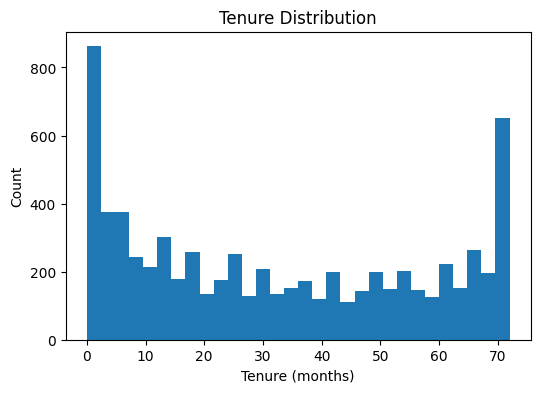

In [12]:
# Task 12 — numerical feature 1: distribution plot
plt.figure(figsize=(6,4))
plt.hist(df['tenure'], bins=30)
plt.title("Tenure Distribution")
plt.xlabel("Tenure (months)")
plt.ylabel("Count")
plt.show()

**Observation:** _(Distribution is bimodal — a large group of customers are very new (0–5 months) and another large group are long-standing (65–72 months), with fewer customers in between.)_

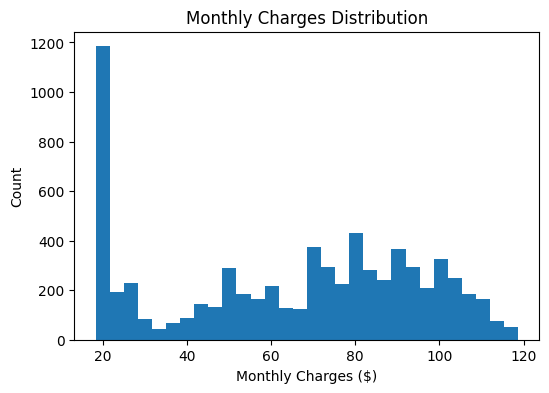

In [13]:
# Task 12 — numerical feature 2: distribution plot
plt.figure(figsize=(6,4))
plt.hist(df['MonthlyCharges'], bins=30)
plt.title("Monthly Charges Distribution")
plt.xlabel("Monthly Charges ($)")
plt.ylabel("Count")
plt.show()

**Observation:** _(Spread mostly between $20–$120, with a noticeable spike around $20 (customers on basic plans with no add-on services).)_

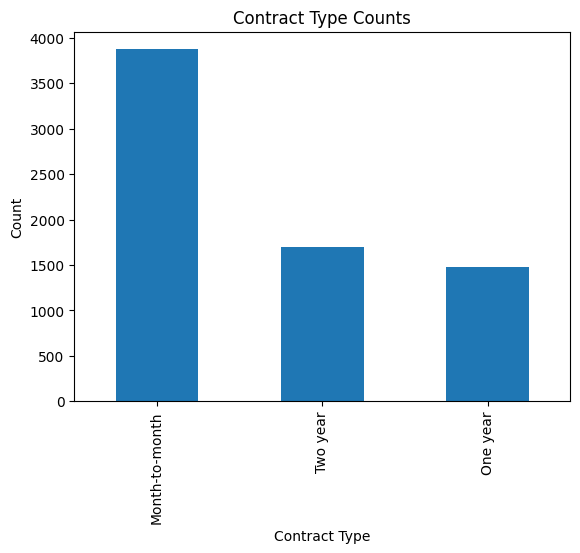

In [14]:
# Task 12 — categorical feature 1: distribution plot
df['Contract'].value_counts().plot(kind='bar')
plt.title("Contract Type Counts")
plt.xlabel("Contract Type")
plt.ylabel("Count")
plt.show()

**Observation:** _(Most customers are on Month-to-month contracts; One year and Two year contracts are much less common.)_

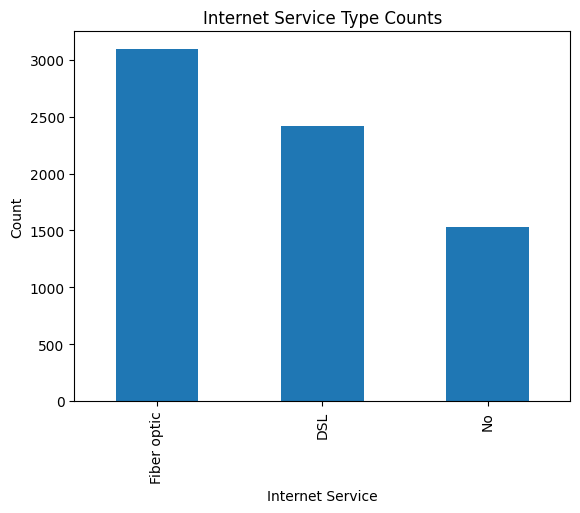

In [15]:
# Task 12 — categorical feature 2: distribution plot
df['InternetService'].value_counts().plot(kind='bar')
plt.title("Internet Service Type Counts")
plt.xlabel("Internet Service")
plt.ylabel("Count")
plt.show()

**Observation:** _(Fiber optic is the most common internet service, followed by DSL; a smaller group has no internet service at all)_

**Answer 13 (outliers / skew and possible explanation):**
_(MonthlyCharges is somewhat right-skewed due to a spike of low-charge customers on basic plans. TotalCharges is also skewed since it depends on tenure × MonthlyCharges — newer customers naturally have lower totals.)_

---

## Part 6 — Target Variable Analysis

The `Churn` column is what you will eventually predict. Before Lab 3, you need to understand its distribution — this has direct consequences for how a model should later be trained and evaluated.

*Concepts/functions you may find useful:* `df['Churn'].value_counts()`, `df['Churn'].value_counts(normalize=True)`

**Tasks**
14. Report the number and percentage of churned vs. non-churned customers. Is the target balanced or imbalanced?
15. In 2–3 sentences, explain why class imbalance might matter when a classification model is trained later — do not describe how to fix it, just why it matters.

Churn
0    5174
1    1869
Name: count, dtype: int64
Churn
0    73.46
1    26.54
Name: proportion, dtype: float64


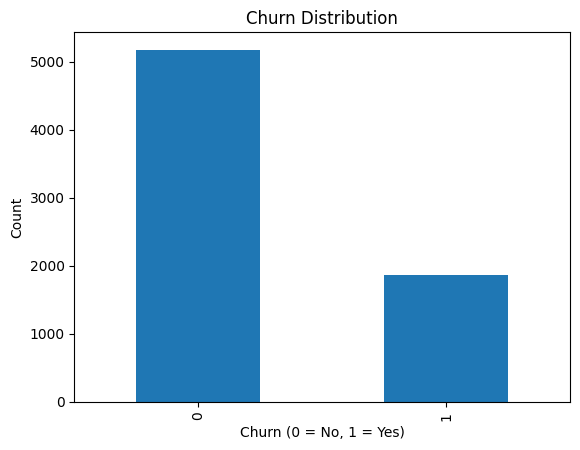

In [16]:
# Task 14 — churn counts and percentages
print(df['Churn'].value_counts())
print((df['Churn'].value_counts(normalize=True) * 100).round(2))

df['Churn'].value_counts().plot(kind='bar')
plt.title("Churn Distribution")
plt.xlabel("Churn (0 = No, 1 = Yes)")
plt.ylabel("Count")
plt.show()

**Answer 14 (balanced or imbalanced?):**
_(The target variable is imbalanced — only about 26.5% of customers churned, while 73.5% stayed.)_

**Answer 15 (why imbalance might matter later):**
_(Because churn (the minority class) is under-represented, a model could get high accuracy just by predicting "No churn" for everyone, while failing to actually identify churners. Metrics like precision, recall, and F1-score will matter more than accuracy for a future model.)_

---

## Part 7 — Bivariate Analysis: Features vs. Churn

Now connect individual features to the target. You choose the appropriate visualization or summary for each feature type — a categorical feature is not explored the same way as a numerical one.

*Concepts/functions you may find useful:* `pd.crosstab(df[col], df['Churn'], normalize='index')`, `df.groupby(col)['Churn']...`, `sns.boxplot(x='Churn', y=col, data=df)`

**Tasks**
16. Investigate at least 2 categorical features (e.g. Contract, InternetService, PaymentMethod) against Churn. For each, record: Observation / Evidence / Possible Explanation.
17. Investigate at least 2 numerical features (e.g. tenure, MonthlyCharges) against Churn using the same Observation / Evidence / Possible Explanation format.

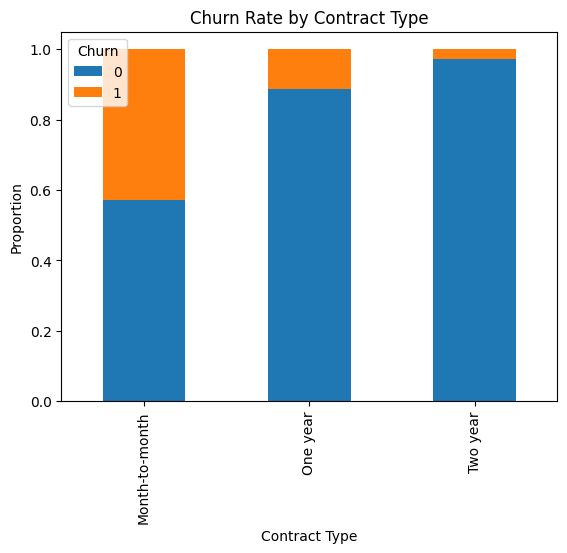

Churn               0      1
Contract                    
Month-to-month  57.29  42.71
One year        88.73  11.27
Two year        97.17   2.83


In [17]:
# Task 16 — categorical feature 1 vs Churn
pd.crosstab(df['Contract'], df['Churn'], normalize='index').plot(kind='bar', stacked=True)
plt.title("Churn Rate by Contract Type")
plt.xlabel("Contract Type")
plt.ylabel("Proportion")
plt.show()

print((pd.crosstab(df['Contract'], df['Churn'], normalize='index') * 100).round(2))

**Observation:** _Month-to-month customers churn far more than customers on longer contracts._
**Evidence:** _Month-to-month churn rate ≈ 42.7%, One year ≈ 11.3%, Two year ≈ 2.8%.._
**Possible Explanation:** _Long-term contracts lock customers in and make switching more costly/inconvenient, so they're less likely to leave.._

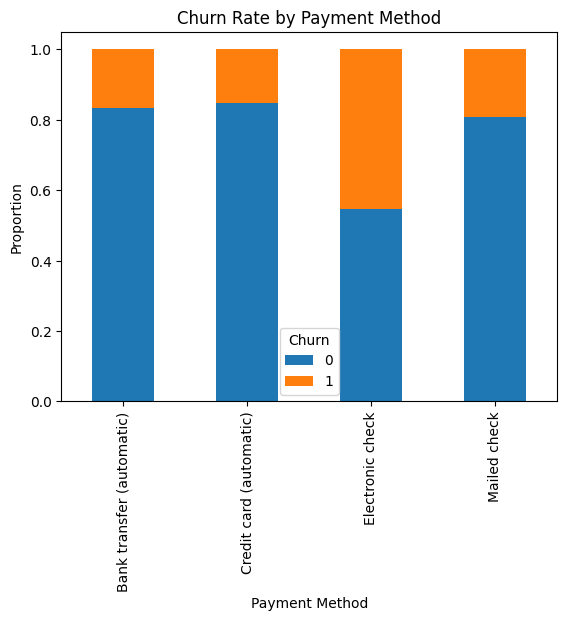

Churn                          0      1
PaymentMethod                          
Bank transfer (automatic)  83.29  16.71
Credit card (automatic)    84.76  15.24
Electronic check           54.71  45.29
Mailed check               80.89  19.11


In [18]:
# Task 16 — categorical feature 2 vs Churn
pd.crosstab(df['PaymentMethod'], df['Churn'], normalize='index').plot(kind='bar', stacked=True)
plt.title("Churn Rate by Payment Method")
plt.xlabel("Payment Method")
plt.ylabel("Proportion")
plt.show()

print((pd.crosstab(df['PaymentMethod'], df['Churn'], normalize='index') * 100).round(2))

**Observation:** _Customers paying by Electronic check churn much more than those using automatic payments.._
**Evidence:** _Electronic check ≈ 45.3% churn vs Credit card (automatic) ≈ 15.2% and Bank transfer (automatic) ≈ 16.7%.._
**Possible Explanation:** _Automatic payments keep customers passively retained; manual electronic check payers may be less engaged or more price-sensitive.._

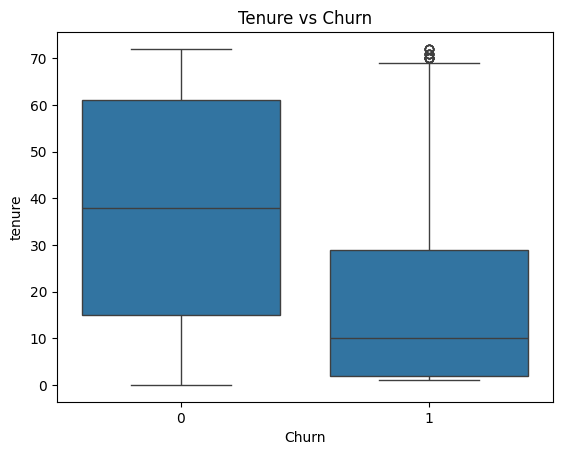

        count       mean        std  min   25%   50%   75%   max
Churn                                                           
0      5174.0  37.569965  24.113777  0.0  15.0  38.0  61.0  72.0
1      1869.0  17.979133  19.531123  1.0   2.0  10.0  29.0  72.0


In [19]:
# Task 17 — numerical feature 1 vs Churn
sns.boxplot(x='Churn', y='tenure', data=df)
plt.title("Tenure vs Churn")
plt.show()

print(df.groupby('Churn')['tenure'].describe())

**Observation:** _Churned customers have noticeably shorter tenure than those who stayed.._
**Evidence:** _Average tenure for churned customers ≈ 18 months vs ≈ 37.5 months for non-churned.._
**Possible Explanation:** _Newer customers are still evaluating the service, so a poor early experience makes them leave sooner.._

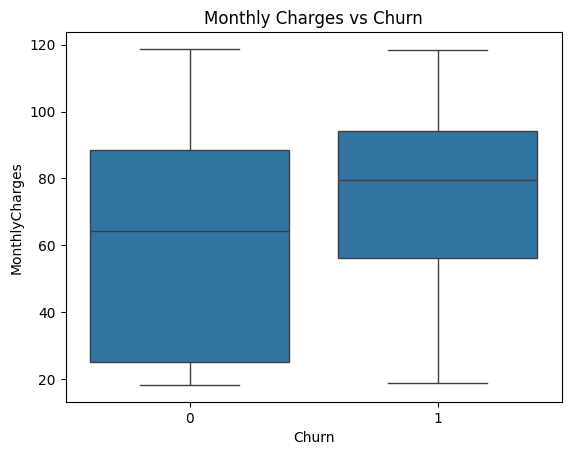

        count       mean        std    min    25%     50%   75%     max
Churn                                                                  
0      5174.0  61.265124  31.092648  18.25  25.10  64.425  88.4  118.75
1      1869.0  74.441332  24.666053  18.85  56.15  79.650  94.2  118.35


In [20]:
# Task 17 — numerical feature 2 vs Churn
sns.boxplot(x='Churn', y='MonthlyCharges', data=df)
plt.title("Monthly Charges vs Churn")
plt.show()

print(df.groupby('Churn')['MonthlyCharges'].describe())

**Observation:** _Churned customers tend to pay higher monthly charges.._
**Evidence:** _Average MonthlyCharges for churned customers ≈ $74.4 vs ≈ $61.3 for non-churned.._
**Possible Explanation:** _Customers paying more may feel they aren't getting enough value, pushing them toward cheaper competitors.._

---

## Part 8 — Correlation & Feature Relationships

Numerical features can be related to each other, not just to the target. Strongly correlated features can cause redundancy problems later, so it's worth knowing about them now.

*Concepts/functions you may find useful:* `df.corr(numeric_only=True)`, `sns.heatmap(corr_matrix, annot=True)`

**Tasks**
18. Compute and visualize the correlation matrix of the numerical features. Which pairs appear most correlated?
19. Does correlation imply causation here? Could any highly correlated features cause problems for a future model? Answer in 2–3 sentences.

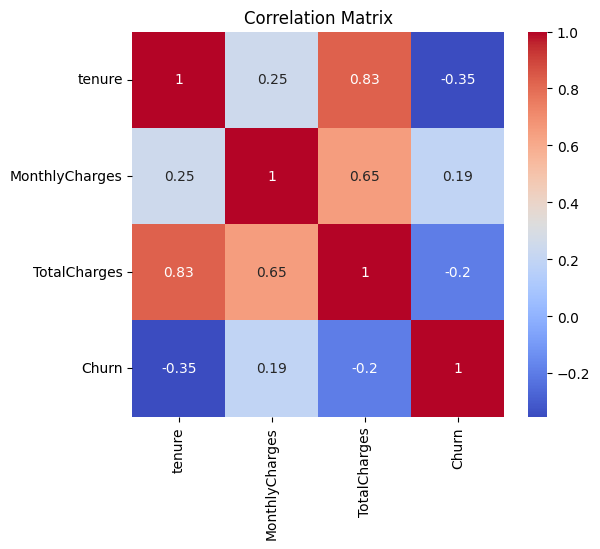

In [21]:
# Task 18 — correlation matrix and heatmap
corr = df[['tenure', 'MonthlyCharges', 'TotalCharges', 'Churn']].corr()

plt.figure(figsize=(6,5))
sns.heatmap(corr, annot=True, cmap='coolwarm')
plt.title("Correlation Matrix")
plt.show()

**Answer 18 (most correlated pairs):**
_(The strongest correlation is between tenure and TotalCharges (≈0.83) — makes sense since longer-tenured customers naturally accumulate higher total charges. MonthlyCharges and TotalCharges are also moderately correlated (≈0.65).)_

**Answer 19 (correlation vs. causation; potential problems):**
_(Correlation doesn't imply causation — it only shows two variables move together, not that one causes the other. The high tenure–TotalCharges correlation suggests redundancy (multicollinearity risk), meaning both may not be needed together in a future model.)_

---

## Part 9 — Data Leakage Awareness

In Lab 3 you will train a classifier. Before that, you must check whether any column contains information that would not realistically be available at the moment of prediction — using such a column would make a model look artificially accurate.

**Tasks**
20. Inspect the columns for anything that looks like it could only be known after a customer has already churned, or that is purely an identifier. List any suspects and explain your reasoning.
21. In 2–3 sentences, explain what would go wrong if such a column were left in the model's input features.

**Answer 20 (suspect columns and reasoning):**
_(customerID is a pure identifier with no predictive information — it should be removed. TotalCharges is technically derived from tenure × MonthlyCharges, making it somewhat redundant, but it's not leakage since it's known at prediction time (not something only available after churn happens). No column in this dataset directly reveals the outcome after the fact.)_

**Answer 21 (what would go wrong):**
_(If an identifier column like customerID is left in the model, it can cause the model to memorize noise or false patterns tied to specific rows instead of learning real relationships. This leads to overfitting and poor generalization on new, unseen customers.)_

---

## Part 10 — ML-Readiness Checklist

Summarize every column's fate in a single table. This is the bridge between EDA and modeling — Lab 3 will use this table directly.

**Task**
22. Complete the ML-readiness table for **every** column in the dataset.

| Column | Type | Role | Action | Reason |
|---|---|---|---|---|
| customerID | Identifier | — | Remove | ... |
| tenure | Numerical | Feature | ... | ... |
| Contract | Categorical | Feature | ... | ... |
| Churn | Categorical | Target | Keep | ... |
| ... | ... | ... | ... | ... |

_(| TotalCharges | Numerical | Feature | Keep | Missing values already fixed |)_

---

## Part 11 — Building the Clean Dataset

Bring together every cleaning decision into one final dataframe, `clean_df`, that Lab 3 can load directly.

> Do **not** split into train/test, encode categorical variables, or train any model — that happens in Lab 3.

**Tasks**
23. Produce `clean_df` with correct data types, missing values handled, duplicates handled, and irrelevant identifier columns removed where justified. Save it (e.g. `clean_churn.csv`) alongside your notebook.
24. Print `df.info()` (or equivalent) for `clean_df` as final proof that every issue identified earlier has been resolved.

In [22]:
# Task 23 — assemble clean_df from your cleaning decisions
clean_df = df.copy()

# ... apply your cleaning steps here ...
clean_df['TotalCharges'] = clean_df['TotalCharges'].fillna(0)
clean_df['SeniorCitizen'] = clean_df['SeniorCitizen'].map({0: 'No', 1: 'Yes'}) if clean_df['SeniorCitizen'].dtype != 'object' else clean_df['SeniorCitizen']
clean_df = clean_df.drop(columns=['customerID'])
# Save the cleaned dataset
clean_df.to_csv("clean_churn.csv", index=False)


In [23]:
# Task 24 — final proof: info() / isnull().sum() / duplicated().sum() on clean_df

print(clean_df.info())
print(clean_df.isnull().sum())
print("Duplicate rows:", clean_df.duplicated().sum())

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 20 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   gender            7043 non-null   str    
 1   SeniorCitizen     0 non-null      str    
 2   Partner           7043 non-null   str    
 3   Dependents        7043 non-null   str    
 4   tenure            7043 non-null   int64  
 5   PhoneService      7043 non-null   str    
 6   MultipleLines     7043 non-null   str    
 7   InternetService   7043 non-null   str    
 8   OnlineSecurity    7043 non-null   str    
 9   OnlineBackup      7043 non-null   str    
 10  DeviceProtection  7043 non-null   str    
 11  TechSupport       7043 non-null   str    
 12  StreamingTV       7043 non-null   str    
 13  StreamingMovies   7043 non-null   str    
 14  Contract          7043 non-null   str    
 15  PaperlessBilling  7043 non-null   str    
 16  PaymentMethod     7043 non-null   str    
 17  Monthl

---

## Part 12 — Key Findings & Final Reflection

Step back from the code and summarize what you actually learned about this dataset and this problem.

**Task 25 — Five Important Findings**

Repeat this block for each of your five findings.

**Finding 1**
- Observation: _..._
- Evidence: _..._
- Interpretation: _..._

**Finding 2**
- Observation: _..._
- Evidence: _..._
- Interpretation: _..._

**Finding 3**
- Observation: _..._
- Evidence: _..._
- Interpretation: _..._

**Finding 4**
- Observation: _..._
- Evidence: _..._
- Interpretation: _..._

**Finding 5**
- Observation: _..._
- Evidence: _..._
- Interpretation: _..._

---

**Task 26 — Final Reflection Questions**

1. What was the most important data-quality issue you found?
   _(Handling the 11 missing TotalCharges values — required investigating the rows first to confirm they all corresponded to new customers (tenure = 0) before deciding on the right fix.)_
2. What was the most interesting pattern you discovered?
   _(How large the churn-rate gap was between contract types — Month-to-month churn is more than 15x higher than Two-year contracts.)_
3. Which feature seems most useful for predicting churn?
   _(Contract, since it shows the clearest and most consistent relationship with churn across categories.)_
4. Which feature should probably not be used, and why?
   _(customerID, since it's a unique identifier with no predictive relationship to churn and could cause the model to overfit on noise.)_
5. What preprocessing will be required before ML modeling (conceptually — do not implement it)?
   _(Encode all categorical variables (one-hot or label encoding) and scale/normalize the numerical features (tenure, MonthlyCharges, TotalCharges) before feeding them into a model.)_
6. What would you do next if you had another 3 hours?
   _(I would engineer new features, like grouping tenure into buckets (e.g., 0–12, 12–24, 24+ months) or creating a "total services subscribed" count, and look deeper into customer segments that combine multiple high-risk factors (e.g., month-to-month + fiber optic + electronic check).)_

---

## Bonus Tasks (Optional)

- Create one additional meaningful visualization not required above.
- Investigate a surprising customer subgroup you didn't expect to find.
- Calculate churn rate across a combination of 2+ customer segments at once.
- Identify one possible feature-engineering opportunity for Lab 3.
- Identify one possible source of bias in this dataset.

In [25]:
# Bonus — optional expl

# 1. Combined segment churn rate (Contract + InternetService)
combo = df.groupby(['Contract', 'InternetService'])['Churn'].mean().round(3) * 100
print(combo)

# 2. Surprising subgroup: triple risk customers
mask = (df['Contract'] == 'Month-to-month') & (df['InternetService'] == 'Fiber optic') & (df['PaymentMethod'] == 'Electronic check')
print("Segment size:", mask.sum())
print("Segment churn rate:", round(df[mask]['Churn'].mean() * 100, 1), "%")
print("Overall churn rate:", round(df['Churn'].mean() * 100, 1), "%")

Contract        InternetService
Month-to-month  DSL                32.2
                Fiber optic        54.6
                No                 18.9
One year        DSL                 9.3
                Fiber optic        19.3
                No                  2.5
Two year        DSL                 1.9
                Fiber optic         7.2
                No                  0.8
Name: Churn, dtype: float64
Segment size: 1307
Segment churn rate: 60.4 %
Overall churn rate: 26.5 %


---

## Submission Checklist

Before submitting, confirm you have:

- [ ] Completed all 26 tasks above, with written interpretation for every chart and decision
- [ ] A working `clean_df`, saved as `clean_churn.csv`
- [ ] A completed ML-readiness table (Part 10) covering every column
- [ ] Five Key Findings written (Part 12)
- [ ] Answered all six Final Reflection questions
- [ ] Committed and pushed this notebook + `clean_churn.csv` to your GitHub repository
- [ ] Added your GitHub repository link at the top of this notebook